# Customer Churn: Explaining the Model

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap
from sklearn.model_selection import train_test_split

plt.style.use("default")

In [3]:
saved = joblib.load("../models/churn_model.joblib")
model_pipe = saved["model"]
threshold = saved["threshold"]

df = pd.read_csv("../data/churn_clean.csv")
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)

X = df.drop(columns=["Churn"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Threshold:", threshold)

Threshold: 0.4


In [4]:
preprocessor = model_pipe.named_steps["prep"]
logreg = model_pipe.named_steps["model"]

feature_names = [name.split("__", 1)[1] for name in preprocessor.get_feature_names_out()]
len(feature_names)

47

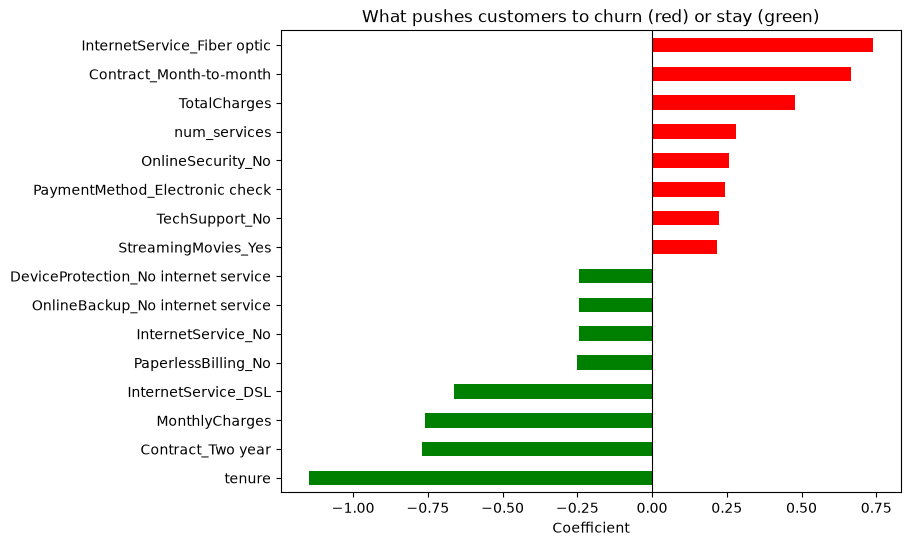

In [5]:
coefs = pd.Series(logreg.coef_[0], index=feature_names).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])

colors = ["green" if c < 0 else "red" for c in top]
top.plot(kind="barh", color=colors, figsize=(8, 6))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("What pushes customers to churn (red) or stay (green)")
plt.xlabel("Coefficient")
plt.savefig("../images/coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
X_train_ready = preprocessor.transform(X_train)
X_test_ready = preprocessor.transform(X_test)

explainer = shap.LinearExplainer(logreg, X_train_ready)
shap_values = explainer(X_test_ready)
shap_values.feature_names = feature_names

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


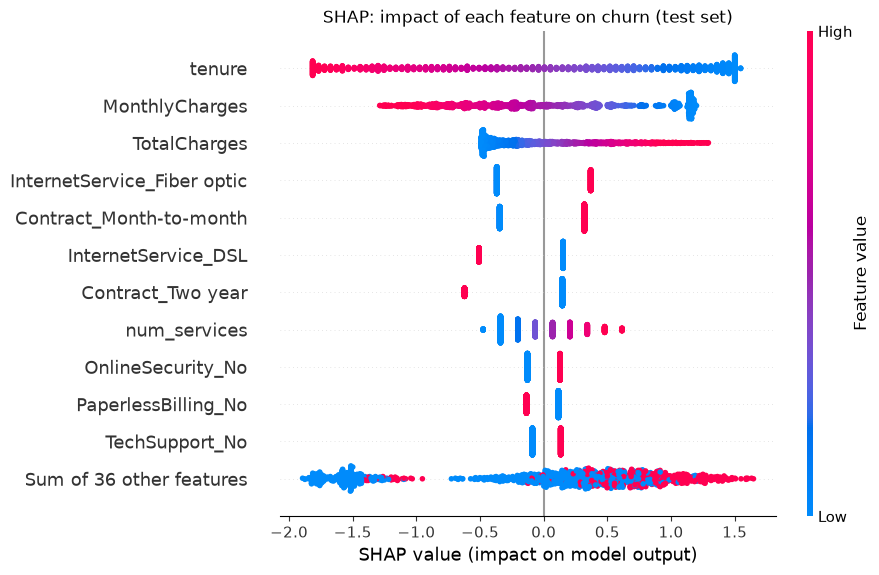

In [7]:
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP: impact of each feature on churn (test set)")
plt.savefig("../images/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
test_proba = model_pipe.predict_proba(X_test)[:, 1]

i = np.argmax(test_proba)
print(f"Churn probability: {test_proba[i]:.1%}  |  Really churned: {y_test.iloc[i]}")
X_test.iloc[i][["tenure", "Contract", "InternetService", "PaymentMethod",
                "TechSupport", "MonthlyCharges"]]

Churn probability: 93.8%  |  Really churned: 1


tenure                            1
Contract             Month-to-month
InternetService         Fiber optic
PaymentMethod      Electronic check
TechSupport                      No
MonthlyCharges                 95.1
Name: 3380, dtype: object

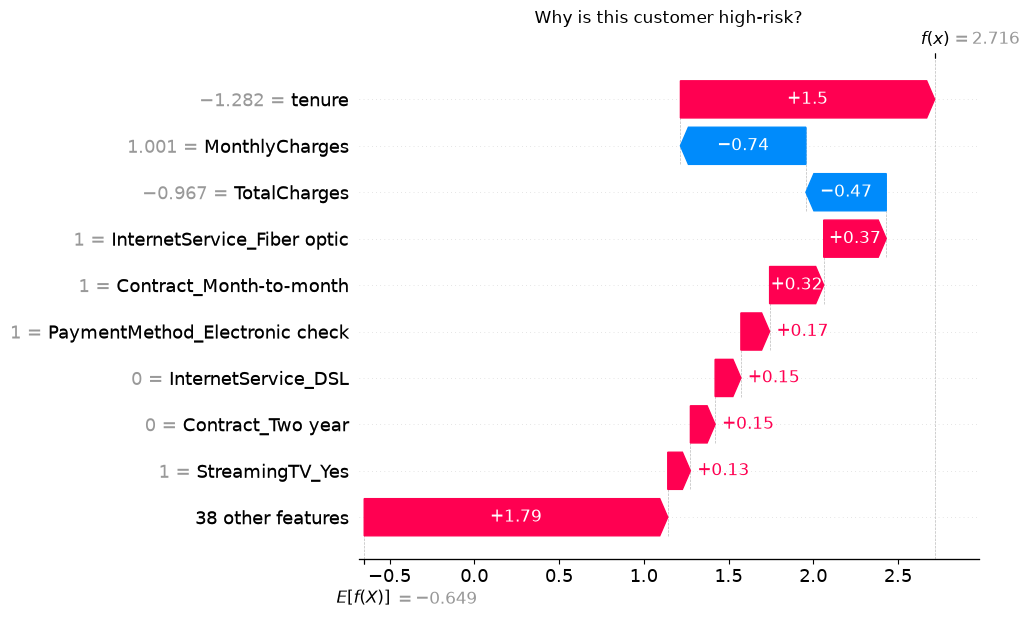

In [9]:
shap.plots.waterfall(shap_values[i], max_display=10, show=False)
plt.title("Why is this customer high-risk?")
plt.savefig("../images/shap_waterfall_high_risk.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
j = np.argmin(test_proba)
print(f"Churn probability: {test_proba[j]:.1%}  |  Really churned: {y_test.iloc[j]}")
X_test.iloc[j][["tenure", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges"]]

Churn probability: 0.6%  |  Really churned: 0


tenure                                    72
Contract                            Two year
InternetService                           No
PaymentMethod      Bank transfer (automatic)
MonthlyCharges                         19.95
Name: 2338, dtype: object

## What drives churn?

**Global (coefficients + SHAP):**
- **Tenure is the strongest factor:** new customers are far more likely to leave.
- **Contract:** month-to-month pushes toward churn; two-year contracts strongly protect.
- **Fiber optic** internet increases churn risk; DSL and no internet reduce it.
- **Electronic check** payment and **no online security / tech support** add risk.
- These match the EDA findings, so the model learned real, sensible patterns.

**A lesson on coefficients:** `MonthlyCharges` has a *negative* coefficient even though
churners pay more on average. Coefficients show each feature's effect *with all other
features held fixed*: high charges mostly come with fiber and extra services, which the
model already counts. Correlated features (like tenure and TotalCharges) share their effect.

**Local (one customer):** the highest-risk test customer (93.8% probability, who did churn)
had 1 month of tenure, a month-to-month contract, fiber optic and electronic check.
SHAP shows tenure as the biggest reason. This lets the retention team see *why* each
customer was flagged and choose the right offer.